This notebook analyses the data previously published by [Thévenot et al. (2015)](https://doi.org/10.1021/acs.jproteome.5b00354) based on the work described in [Mendez et al. (2019)](https://doi.org/10.1007/s11306-019-1612-4).
The data was made "dirty" and then "cleaned" with different imputation strategies.

This notebook was written by Nikolai Egorov

In [11]:
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer

from sklearn.svm        import SVC
from sklearn.ensemble   import RandomForestClassifier

from sklearn.model_selection    import train_test_split
from sklearn.pipeline           import Pipeline
from sklearn.preprocessing      import FunctionTransformer, StandardScaler
from sklearn.metrics            import roc_auc_score

from sklearn.inspection import permutation_importance
print('All packages successfully loaded')

All packages successfully loaded


# Workflow of the project:
1. We pick our data (1 dataset) from the last project and choose 2 different ML methods.
2. Make the dataset "dirty": artificially alter the data by changing or removing values. The changes should affect 10% and 50% of the data. In the end, we get 4 altered datasets.
3. For datasets with removed values: impute missing values using at least 2 methods.
4. Perform analysis with both ML methods on all 11 datasets: 1 original, 4 dirty and 6 cleaned datasets.
5. Statistics: extract 5 most important metabolites, compare results regarding model performance and the extracted 
features.

Author: Nikolai Egorov

## I. Extract data.

For this step we use MTBLS90 dataset from the last project.

Description: A plasma LC-MS dataset consisting of 189 named metabolites. This was a large prospective epidemiological study of men and women at age 70 living in Uppsala, Sweden. For the purpose of this study, we compare males (Class=1; n=485) and females (Class=0; n=483) in a binary discriminant analysis.

Source: https://cimcb.github.io/MetabComparisonBinaryML/

In [12]:
# Extract the data
# current directory
entries = os.scandir('.')

# two levels up, then into project_1/data
rel_path = "../../PROJECT_1/data/MTBLS90.xlsx"
# df = pd.read_excel(rel_path, engine="openpyxl")
DataTable = pd.read_excel(rel_path, sheet_name='Data')
PeakTable = pd.read_excel(rel_path, sheet_name='Peak')

# Extract PeakList
PeakList = PeakTable['Name']

C:\Users\egoro\Documents\mlails-2025\venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
C:\Users\egoro\Documents\mlails-2025\venv\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


## II: Make the data "dirty"

2 strategies for making the dataset "dirty":
1. Remove values: given a dataset and a fraction, set a fraction of cells in the dataset to NaN.
2. Change values: Given a dataset and a fraction, assign new values to a fraction of cells in the dataset. Draw randomly new values from a certain range/set to assign them to the cells.

Data "dirtying" affects only labels in this experiment.

In [13]:
def remove_values(df: pd.DataFrame, frac: float, random_state: int = None) -> pd.DataFrame:
    """
    Randomly set a fraction `frac` of **cells** in the DataFrame to NaN.
    """
    # ensure reproducibility
    rng = np.random.default_rng(random_state)
    # Use copies to keep the original dataset unchanged
    corrupted = df.copy(deep=True)
    # ensure ints become floats, so setting NaN works too
    int_cols = corrupted.select_dtypes(include='integer').columns
    corrupted[int_cols] = corrupted[int_cols].astype(float)
    
    # total number of cells
    n_cells = corrupted.size
    # how many to remove
    n_remove = int(np.floor(frac * n_cells))
    
    # pick random linear indices
    remove_indices = rng.choice(n_cells, size=n_remove, replace=False)
    # unravel into row, col
    rows, cols = np.unravel_index(remove_indices, corrupted.shape)
    
    # set those positions to NaN
    for r, c in zip(rows, cols):
        corrupted.iat[r, c] = np.nan
        
    return corrupted


def change_values(df: pd.DataFrame, frac: float, random_state: int = None) -> pd.DataFrame:
    """
    Randomly change a fraction `frac` of **cells** by drawing new values:
     - numeric columns: draw uniform between that column’s min/max
     - categorical/object columns: draw randomly from that column’s observed values
    """
    rng = np.random.default_rng(random_state)
    corrupted = df.copy(deep=True)
    # ensure ints become floats, so setting NaN works too
    int_cols = corrupted.select_dtypes(include='integer').columns
    corrupted[int_cols] = corrupted[int_cols].astype(float)
    
    # select which cells to change
    n_cells = corrupted.size    # total number of cells
    n_change = int(np.floor(frac * n_cells))    # cells to change
    # randomly pick n_change distinct integers in [0, n_cells) of size n_change
    change_indices = rng.choice(n_cells, size=n_change, replace=False)
    # converts these flat indices into (row, column) pairs
    rows, cols = np.unravel_index(change_indices, corrupted.shape)
    
    for r, c in zip(rows, cols):
        col = corrupted.columns[c]
        val = corrupted.iat[r, c]
        # identify column type
        # find that column’s observed minimum/maximum
        col_min, col_max = corrupted[col].min(), corrupted[col].max()
        # draw a random float uniformly in [min, max)
        new_val = rng.uniform(col_min, col_max)
        
        corrupted.iat[r, c] = new_val
        
    return corrupted

In [14]:
# Create the four “dirty” datasets:
#    - 10% missing, 50% missing
#    - 10% changed, 50% changed

dt_features = DataTable[PeakList].copy()

df_rm10 = remove_values(dt_features, 0.10, random_state=42)
df_rm50 = remove_values(dt_features, 0.50, random_state=42)

df_ch10 = change_values(dt_features, 0.10, random_state=42)
df_ch50 = change_values(dt_features, 0.50, random_state=42)

Look at the data.

Here we look at the results of "dirtying". First we look at the summary of original dataset. We observe total count of cells in each column, mean, std, min and max values and quartiles as well. Then we calculate total number of missing/changed cells.

In [15]:
print("\nCLEAN vs REMOVED COMPARISON:")
print("\nCLEAN DESCRIBE:")
print(dt_features.describe())
print("\n__________________________________________________________________________________")
print("\nDIRTY DESCRIBE:")
print("\n___________________________________10% STRENGTH___________________________________")
print(df_rm10.describe())
print("\n__________________________________________________________________________________")
print("\n___________________________________50% STRENGTH___________________________________")
print(df_rm50.describe())


CLEAN vs REMOVED COMPARISON:

CLEAN DESCRIBE:
               M1          M2          M3          M4          M5          M6  \
count  968.000000  968.000000  968.000000  968.000000  968.000000  968.000000   
mean    15.100309   14.588205   12.993140   11.916599   11.538797   15.371513   
std      0.287554    0.333544    1.187480    0.783079    0.484311    0.408534   
min     14.186670   13.273450    8.222473    6.885203    8.545572   14.177460   
25%     14.915625   14.358245   12.116768   11.428658   11.275956   15.072188   
50%     15.108960   14.581345   12.749361   11.966888   11.574298   15.344485   
75%     15.298583   14.807030   14.057987   12.426928   11.846193   15.644862   
max     15.994000   16.419860   16.143734   14.050150   12.834166   17.036720   

               M7          M8          M9         M10  ...        M180  \
count  968.000000  968.000000  968.000000  968.000000  ...  968.000000   
mean    17.197264   12.128846    7.836700   14.129326  ...   21.295237   
s

In [16]:
# For 10% strength
# Total count of newly missing cells
print("\n_______________________10% STRENGTH_______________________")
mask_new = df_rm10.isna() & ~dt_features.isna()
total_removed = mask_new.sum().sum()
print(f"Total removed cells: {total_removed}")

# Per-column
removed_per_col = mask_new.sum()
print("Removed per column:\n", removed_per_col)

# Overall percentage
n_cells = dt_features.shape[0] * dt_features.shape[1]
print(f"Removed percentage: {total_removed/n_cells:.1%}")

# For 50% strength
# Total count of newly missing cells
print("\n_______________________50% STRENGTH_______________________")
mask_new = df_rm50.isna() & ~dt_features.isna()
total_removed = mask_new.sum().sum()
print(f"\nTotal removed cells: {total_removed}")

# Per-column
removed_per_col = mask_new.sum()
print("Removed per column:\n", removed_per_col)

# Overall percentage
n_cells = dt_features.shape[0] * dt_features.shape[1]
print(f"Removed percentage: {total_removed/n_cells:.1%}")


_______________________10% STRENGTH_______________________
Total removed cells: 18295
Removed per column:
 M1       97
M2      106
M3       97
M4       97
M5       92
       ... 
M185     94
M186     94
M187    100
M188    101
M189    103
Length: 189, dtype: int64
Removed percentage: 10.0%

_______________________50% STRENGTH_______________________

Total removed cells: 91476
Removed per column:
 M1      490
M2      489
M3      482
M4      474
M5      483
       ... 
M185    472
M186    456
M187    488
M188    476
M189    479
Length: 189, dtype: int64
Removed percentage: 50.0%


In [17]:
print("\n_______________________10% STRENGTH_______________________")
# Compute absolute difference
diff = (df_ch10 - dt_features).abs()

# Build a mask of cells that actually changed
mask_changed = diff > 0

# Total number of altered cells
total_changed = mask_changed.sum().sum()
print(f"Total changed cells: {total_changed}")

# Per-column counts
changed_per_col = mask_changed.sum()
print("Changed per column:\n", changed_per_col)

print("\n_______________________50% STRENGTH_______________________")
# Compute absolute difference
diff = (df_ch50 - dt_features).abs()

# Build a mask of cells that actually changed
mask_changed = diff > 0

# Total number of altered cells
total_changed = mask_changed.sum().sum()
print(f"Total changed cells: {total_changed}")

# Per-column counts
changed_per_col = mask_changed.sum()
print("Changed per column:\n", changed_per_col)


_______________________10% STRENGTH_______________________
Total changed cells: 18295
Changed per column:
 M1       97
M2      106
M3       97
M4       97
M5       92
       ... 
M185     94
M186     94
M187    100
M188    101
M189    103
Length: 189, dtype: int64

_______________________50% STRENGTH_______________________
Total changed cells: 91476
Changed per column:
 M1      490
M2      489
M3      482
M4      474
M5      483
       ... 
M185    472
M186    456
M187    488
M188    476
M189    479
Length: 189, dtype: int64


## III. Clean the data

For cleaning we use 2 approaches: data imputation and data removal. For data imputation we use 2 approaches: imputation with KNN imputer and with iterative imputer. Data removal is self-explanatory: we just remove rows with empty cells.

In [18]:
# https://machinelearningmastery.com/handle-missing-data-python/

# For a data point with missing values, this technique identifies the K closest points under a chosen distance metric (Euclidean by default). 
# The number of closest points or neighbors is specified by the n_neighbors parameter.
def clean_knn(df, n_neighbors=4):
    imputer = KNNImputer(n_neighbors=n_neighbors)
    imputed = imputer.fit_transform(df)
    return pd.DataFrame(imputed, index=df.index, columns=df.columns)

# The IterativeImputer predicts the missing values of a feature by modeling it as a function of other features. 
# The imputer, therefore, predicts the missing values of a feature using the other features as predictors.
# It then imputes all missing features in a round-robin fashion. 
# This imputation continues iteratively for max_iter number of times, and is set to 10 by default.
def clean_iterative(df, random_state=42):
    imputer = IterativeImputer(max_iter=10, tol=1e-2, verbose=2, random_state=random_state)

    # impute in log space to avoid negative values
    log_df = np.log(df)
    log_imputed = imputer.fit_transform(log_df)
    imputed = np.exp(log_imputed)
    return pd.DataFrame(imputed, index=df.index, columns=df.columns)

In [19]:
# Cleaned datasets using KNN
clean_knn_rm_10 = clean_knn(df_rm10)
clean_knn_rm_50 = clean_knn(df_rm50)

# Cleaned datasets using Iterative Regression
clean_iter_rm_10 = clean_iterative(df_rm10)
clean_iter_rm_50 = clean_iterative(df_rm50)

[IterativeImputer] Completing matrix with shape (968, 189)
[IterativeImputer] Ending imputation round 1/10, elapsed time 7.84
[IterativeImputer] Change: 1.6348149565733419, scaled tolerance: 0.03179249781579758 
[IterativeImputer] Ending imputation round 2/10, elapsed time 15.54
[IterativeImputer] Change: 0.23418590435805475, scaled tolerance: 0.03179249781579758 
[IterativeImputer] Ending imputation round 3/10, elapsed time 25.00
[IterativeImputer] Change: 0.10419077365232532, scaled tolerance: 0.03179249781579758 
[IterativeImputer] Ending imputation round 4/10, elapsed time 32.84
[IterativeImputer] Change: 0.05702913493652417, scaled tolerance: 0.03179249781579758 
[IterativeImputer] Ending imputation round 5/10, elapsed time 40.57
[IterativeImputer] Change: 0.04405922630499548, scaled tolerance: 0.03179249781579758 
[IterativeImputer] Ending imputation round 6/10, elapsed time 48.31
[IterativeImputer] Change: 0.03394858336682116, scaled tolerance: 0.03179249781579758 
[IterativeImp

Now let's observe a dataset obtained with "Get rid of the row with missing values" method.
We can see, that there are now rows even for strength 10% left. Therefore, analysis is not possible

In [20]:
# Remove rows with missing values
clean_drop_rm_10 = df_rm10.dropna()
clean_drop_rm_50 = df_rm50.dropna()

print(clean_drop_rm_10.shape, clean_drop_rm_50.shape)

(0, 189) (0, 189)


 ## IV. Perform analysis with ML methods. 
 
For this experiment we use Random Forests and Support Vector Machines algorithm from the last project.

Start with data preprocessing.

In [21]:
def preprocess_data(
        X,
        y,
        test_size: float = 1/3,
        random_state: int = 42
                    ):
    
    # Split into train/test
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        stratify=y,
        random_state=random_state
    )
    
    # Build a pipeline that logs then standard‐scales
    pipeline = Pipeline([
        ('log', FunctionTransformer(np.log, validate=True)),
        ('scale', StandardScaler())
    ])
    
    # Fit the pipeline on train, transform train & test
    X_train_scaled = pipeline.fit_transform(X_train)
    X_test_scaled  = pipeline.transform(X_test)
    
    return X_train_scaled, X_test_scaled, y_train, y_test

Now feed the data to the model using the best hyperparams from PROJECT_1.

In [22]:
def perform_svm(X,y):
    X_train_scaled, X_test_scaled, y_train, y_test = preprocess_data(X,y)
    C = 0.01
    model = SVC(C=C, kernel='linear', probability=True, random_state=42)
    model.fit(X_train_scaled, y_train)
    y_scores  = model.decision_function(X_test_scaled)
    auc = roc_auc_score(y_test, y_scores)
    return model, auc, X_train_scaled

def perform_rf(X,y):
    X_train_scaled, X_test_scaled, y_train, y_test = preprocess_data(X,y)
    model = RandomForestClassifier(
        criterion='gini',
        max_depth=7,
        max_features='sqrt',
        max_leaf_nodes=None,
        min_samples_leaf=0.01,
        min_samples_split=2,
        n_estimators=100,
        random_state=42,
        n_jobs=-1                   
    )
    model.fit(X_train_scaled, y_train)
    y_scores  = model.predict_proba(X_test_scaled)[:, 1]
    auc = roc_auc_score(y_test, y_scores )
    return model, auc, X_test_scaled, y_test

In [23]:
# List all datasets
datasets = {"original dataset": dt_features, 
            
            "10% change": df_ch10,
            "50% change": df_ch50,
            "knn clean rm 10%": clean_knn_rm_10,
            "knn clean rm 50%": clean_knn_rm_50,
            "iterative clean rm 10%": clean_iter_rm_10,
            "iterative clean rm 50%": clean_iter_rm_50,
            }

In [24]:
y = DataTable['Class'].values
results = []
models = {}

for name, X in datasets.items():
    svm_model, auc_svm, X_train_scaled = perform_svm(X, y)
    rf_model, auc_rf, X_test_scaled, y_test = perform_rf(X, y)
    models[name] = (
        svm_model,
        rf_model,
        X_train_scaled,
        X_test_scaled,
        y_test
    )
    results.append({
        'dataset': name,
        'SVM_AUC': auc_svm,
        'RF_AUC':  auc_rf
    })

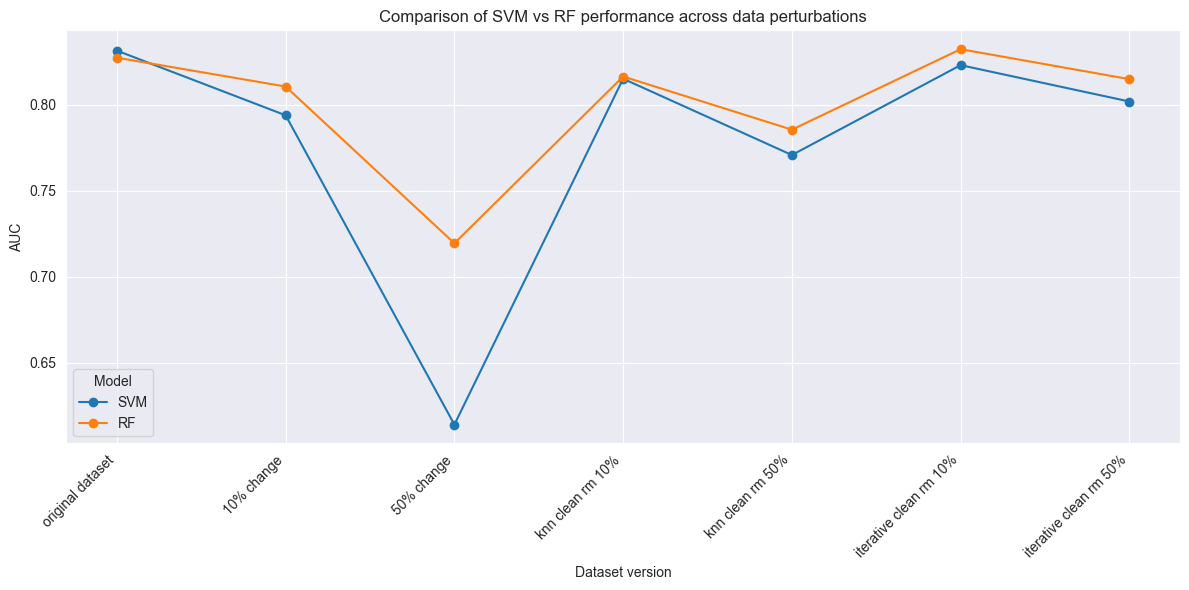

In [25]:
# turn into long form for easy plotting
results_df = pd.DataFrame(results)
plot_df = results_df.melt(
    id_vars='dataset',
    value_vars=['SVM_AUC','RF_AUC'],
    var_name='Model',
    value_name='AUC'
)
plot_df['Model'] = plot_df['Model'].str.replace('_AUC','')  # tidy up names
    
# Sort datasets in the order you inserted them
plot_df['dataset'] = pd.Categorical(
    plot_df['dataset'],
    categories=list(datasets.keys()),
    ordered=True
    )
    
# Plot
plt.figure(figsize=(12,6))
for model in plot_df['Model'].unique():
    sub = plot_df[plot_df['Model']==model]
    plt.plot(
        sub['dataset'],
        sub['AUC'],
        marker='o',
        label=model
    )
    
plt.xticks(rotation=45, ha='right')
plt.xlabel('Dataset version')
plt.ylabel('AUC')
plt.title('Comparison of SVM vs RF performance across data perturbations')
plt.legend(title='Model')
plt.tight_layout()
plt.show()

Since we cannot evaluate the model with removed cells (NaNs cant be feeded to the model), we evaluate only 7 models: 1 original, 2 with changed values and 4 "cleaned". The comparison can be observed on the plot above

## V. Extract important features

Top 5 important features by SVM

In [26]:
# build a dict for fast lookup
id_to_name = dict(zip(PeakTable['Name'], PeakTable['Label']))
for name, (svm_model, rf_model, X_train_s, X_test_s, y_test) in models.items():
    # Compute feature importances
    weights = svm_model.coef_.ravel()
    feature_ids = (
        X_train_s.columns 
        if hasattr(X_train_s, 'columns') 
        else [f"M{i}" for i in range(len(weights))]
    )
    imp = pd.Series(np.abs(weights), index=feature_ids)
    
    # Get top-N by absolute weight
    N = 5
    topN = imp.sort_values(ascending=False).head(N)
    topN.index = [id_to_name.get(fid, fid) for fid in topN.index]
    
    print(f"\n Top {N} metabolites by |weight|: {name}\n", topN)


 Top 5 metabolites by |weight|: original dataset
 Theobromine                 0.199341
C12 Carnitine               0.176507
Choline                     0.170781
1,3,7-Trimethyluric acid    0.160591
L-Phenylalanine             0.159986
dtype: float64

 Top 5 metabolites by |weight|: 10% change
 Theobromine                                               0.227370
Ornithine                                                 0.178676
3-Pyridylacetic acid|trigonelline                         0.176111
Ceramide phosphoethanolamine(35:2)|Sphingomyelin(32:2)    0.175802
Choline                                                   0.174798
dtype: float64

 Top 5 metabolites by |weight|: 50% change
 e-Caprolactam                                                          0.252016
Monoacylglycerol(18:0)                                                 0.225073
gamma-Glutamyl-leucine                                                 0.188109
L-Proline                                                            

Top 5 important features by Random Forests

In [27]:
# Build a Name→Label dict
name_to_label = dict(zip(PeakTable['Name'], PeakTable['Label']))
for name, (svm_model, rf_model, X_train_s, X_test_s, y_test) in models.items():
    # run on your held-out test set
    perm = permutation_importance(
        rf_model, 
        X_test_s, 
        y_test, 
        n_repeats=10, 
        random_state=0, 
        n_jobs=-1
    )
    
    # sort by mean importance
    perm_idx = perm.importances_mean.argsort()[::-1][:5]
    
    print(f"\n Top features by permutation importance: {name}\n")
    for i in perm_idx:
        name = PeakList[i]
        label = name_to_label[name]
        mean_imp = perm.importances_mean[i]
        std_imp  = perm.importances_std[i]
        print(f"{label}: {mean_imp:.4f} ± {std_imp:.4f}")


 Top features by permutation importance: original dataset

Creatine: 0.0201 ± 0.0072
Creatinine: 0.0167 ± 0.0062
Linoleyl carnitine: 0.0071 ± 0.0048
Uric acid: 0.0062 ± 0.0050
Gamma-Tocopherol: 0.0059 ± 0.0026

 Top features by permutation importance: 10% change

Phosphatidylcholine(28:2): 0.0105 ± 0.0089
Creatine: 0.0102 ± 0.0069
Uric acid: 0.0040 ± 0.0031
Creatinine: 0.0040 ± 0.0055
D-Urobilinogen|I-Urobilin: 0.0031 ± 0.0028

 Top features by permutation importance: 50% change

Ceramide phosphoethanolamine(34:1): 0.0186 ± 0.0062
Ceramide phosphoethanolamine(35:2)|Sphingomyelin(32:2): 0.0152 ± 0.0070
Arachidonic acid: 0.0118 ± 0.0055
Monoacylglycerol(16:1): 0.0105 ± 0.0050
1,2-dipalmitoyl-sn-glycero-3-phosphocholine: 0.0099 ± 0.0043

 Top features by permutation importance: knn clean rm 10%

Creatine: 0.0084 ± 0.0050
Betaine: 0.0028 ± 0.0100
Ceramide phosphoethanolamine(37:2)|Sphingomyelin(34:2): 0.0025 ± 0.0030
Phosphatidylcholine(34:5)|Phosphoethanolamine(37:5): 0.0022 ± 0.0014
L-P